In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
df = pd.read_csv("base05_mapa_risco.csv")
display(df)

,id_entidade,taxa_chargeback,volume_noturno,variabilidade_ticket,proporcao_cartao_nao_presente,velocidade_transacoes,volume_financeiro,diversidade_clientes,tempo_relacionamento,concentracao_destinos,tipo_entidade
0,E000001,0.2274,0.2834,0.3650,0.5471,0.3669,0.5983,0.5292,0.3934,0.3951,portador
1,E000002,0.2503,0.3158,0.5163,0.5128,0.3722,0.6552,0.5501,0.4239,0.3561,portador
2,E000003,0.1333,0.1640,0.2101,0.2991,0.2424,0.2677,0.6529,0.6451,0.2714,portador
3,E000004,0.2959,0.3170,0.3569,0.5494,0.4686,0.7016,0.4031,0.3692,0.4466,lojista
4,E000005,0.1625,0.0928,0.1658,0.3188,0.0984,0.3295,0.7341,0.5933,0.2279,lojista
...,...,...,...,...,...,...,...,...,...,...,...
5995,E005996,0.2007,0.3172,0.3904,0.5081,0.3667,0.5596,0.5302,0.6045,0.4021,lojista
5996,E005997,0.2752,0.2885,0.4837,0.6014,0.4437,0.7077,0.3912,0.3793,0.4719,portador
5997,E005998,0.1776,0.2896,0.4335,0.5944,0.3944,0.7592,0.3907,0.5223,0.3985,portador
5998,E005999,0.1799,0.2633,0.2484,0.1267,0.2296,0.4638,0.8226,0.8714,0.0960,portador


Pré-processamento

In [2]:
# Variáveis que nao ajudam a calcular distancia
X = df.drop(columns=["id_entidade", "tipo_entidade"])

# atributos selecionados
print("Variáveis utilizadas:")
print(X.columns.tolist())

print("\nQuantidade de atributos:", X.shape[1])

Variáveis utilizadas:
['taxa_chargeback', 'volume_noturno', 'variabilidade_ticket', 'proporcao_cartao_nao_presente', 'velocidade_transacoes', 'volume_financeiro', 'diversidade_clientes', 'tempo_relacionamento', 'concentracao_destinos']

Quantidade de atributos: 9


In [3]:
print("Quantidade de linhas:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

print("\nTipos de dados:")
display(df.dtypes.to_frame("Tipo"))

print("\nQuantidade por tipo de entidade:")
display(df["tipo_entidade"].value_counts())

print("\nInformações gerais:")
df.info()

Quantidade de linhas: 6000
Quantidade de colunas: 11

Tipos de dados:


,Tipo
id_entidade,object
taxa_chargeback,float64
volume_noturno,float64
variabilidade_ticket,float64
proporcao_cartao_nao_presente,float64
velocidade_transacoes,float64
volume_financeiro,float64
diversidade_clientes,float64
tempo_relacionamento,float64
concentracao_destinos,float64



Quantidade por tipo de entidade:


,count
tipo_entidade,
portador,3967
lojista,2033



Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_entidade                    6000 non-null   object 
 1   taxa_chargeback                6000 non-null   float64
 2   volume_noturno                 6000 non-null   float64
 3   variabilidade_ticket           6000 non-null   float64
 4   proporcao_cartao_nao_presente  6000 non-null   float64
 5   velocidade_transacoes          6000 non-null   float64
 6   volume_financeiro              6000 non-null   float64
 7   diversidade_clientes           6000 non-null   float64
 8   tempo_relacionamento           6000 non-null   float64
 9   concentracao_destinos          6000 non-null   float64
 10  tipo_entidade                  6000 non-null   object 
dtypes: float64(9), object(2)
memory usage: 515.8+ KB


verificar dados ausentes

In [4]:
# Valores ausentes por coluna
ausentes = df.isnull().sum()

display(
    pd.DataFrame({
        "Ausentes": ausentes,
        "Percentual (%)": ausentes / len(df) * 100
    })
)

print("Total de valores ausentes:", ausentes.sum())

# Verificar campos textuais vazios
colunas_texto = df.select_dtypes(include="object")

print("\nCampos textuais vazios:")
print(colunas_texto.apply(
    lambda col: col.str.strip().eq("").sum()
))

# Verificar valores infinitos
print("\nValores infinitos:")
print(np.isinf(X.to_numpy()).sum())

,Ausentes,Percentual (%)
id_entidade,0,0.0
taxa_chargeback,0,0.0
volume_noturno,0,0.0
variabilidade_ticket,0,0.0
proporcao_cartao_nao_presente,0,0.0
velocidade_transacoes,0,0.0
volume_financeiro,0,0.0
diversidade_clientes,0,0.0
tempo_relacionamento,0,0.0
concentracao_destinos,0,0.0


Total de valores ausentes: 0

Campos textuais vazios:
id_entidade      0
tipo_entidade    0
dtype: int64

Valores infinitos:
0


verificar se tem dados duplicados

In [5]:
# Registros totalmente duplicados
print("Linhas duplicadas:")
print(df.duplicated().sum())

# Identificadores repetidos
print("\nIDs duplicados:")
print(df["id_entidade"].duplicated().sum())

# Registros iguais ignorando o ID
print("\nDuplicatas sem considerar o ID:")
print(
    df.drop(columns=["id_entidade"])
      .duplicated()
      .sum()
)

Linhas duplicadas:
0

IDs duplicados:
0

Duplicatas sem considerar o ID:
0


todos os valores já estao normalizados

In [6]:
# Estatísticas das variáveis numéricas
display(X.describe().T.round(4))

# Verificar a escala
escala = pd.DataFrame({
    "Mínimo": X.min(),
    "Máximo": X.max(),
    "Média": X.mean(),
    "Desvio padrão": X.std(),
    "Assimetria": X.skew()
})

display(escala.round(4))

print("Todos os valores estão entre 0 e 1?")
print(((X >= 0) & (X <= 1)).all().all())

,count,mean,std,min,25%,50%,75%,max
taxa_chargeback,6000.0,0.1984,0.1057,0.0,0.1325,0.1710,0.2318,1.0
volume_noturno,6000.0,0.2515,0.1605,0.0,0.1530,0.2008,0.2854,1.0
variabilidade_ticket,6000.0,0.3455,0.1459,0.0,0.2395,0.3196,0.4240,1.0
proporcao_cartao_nao_presente,6000.0,0.4554,0.1511,0.0,0.3468,0.4550,0.5612,1.0
velocidade_transacoes,6000.0,0.3009,0.1359,0.0,0.2061,0.2724,0.3632,1.0
volume_financeiro,6000.0,0.5480,0.1626,0.0,0.4263,0.5480,0.6704,1.0
diversidade_clientes,6000.0,0.5837,0.1596,0.0,0.4777,0.5971,0.7024,1.0
tempo_relacionamento,6000.0,0.5691,0.1541,0.0,0.4714,0.5876,0.6839,1.0
concentracao_destinos,6000.0,0.3229,0.1430,0.0,0.2206,0.2910,0.3934,1.0


,Mínimo,Máximo,Média,Desvio padrão,Assimetria
taxa_chargeback,0.0,1.0,0.1984,0.1057,1.9361
volume_noturno,0.0,1.0,0.2515,0.1605,1.9180
variabilidade_ticket,0.0,1.0,0.3455,0.1459,0.8525
proporcao_cartao_nao_presente,0.0,1.0,0.4554,0.1511,0.0228
velocidade_transacoes,0.0,1.0,0.3009,0.1359,1.2236
volume_financeiro,0.0,1.0,0.5480,0.1626,0.0027
diversidade_clientes,0.0,1.0,0.5837,0.1596,-0.4238
tempo_relacionamento,0.0,1.0,0.5691,0.1541,-0.4874
concentracao_destinos,0.0,1.0,0.3229,0.1430,1.0949


Todos os valores estão entre 0 e 1?
True


dados comparados com a distribuiçao gaussiana para ver se é possivel achar uma cauda, outliers

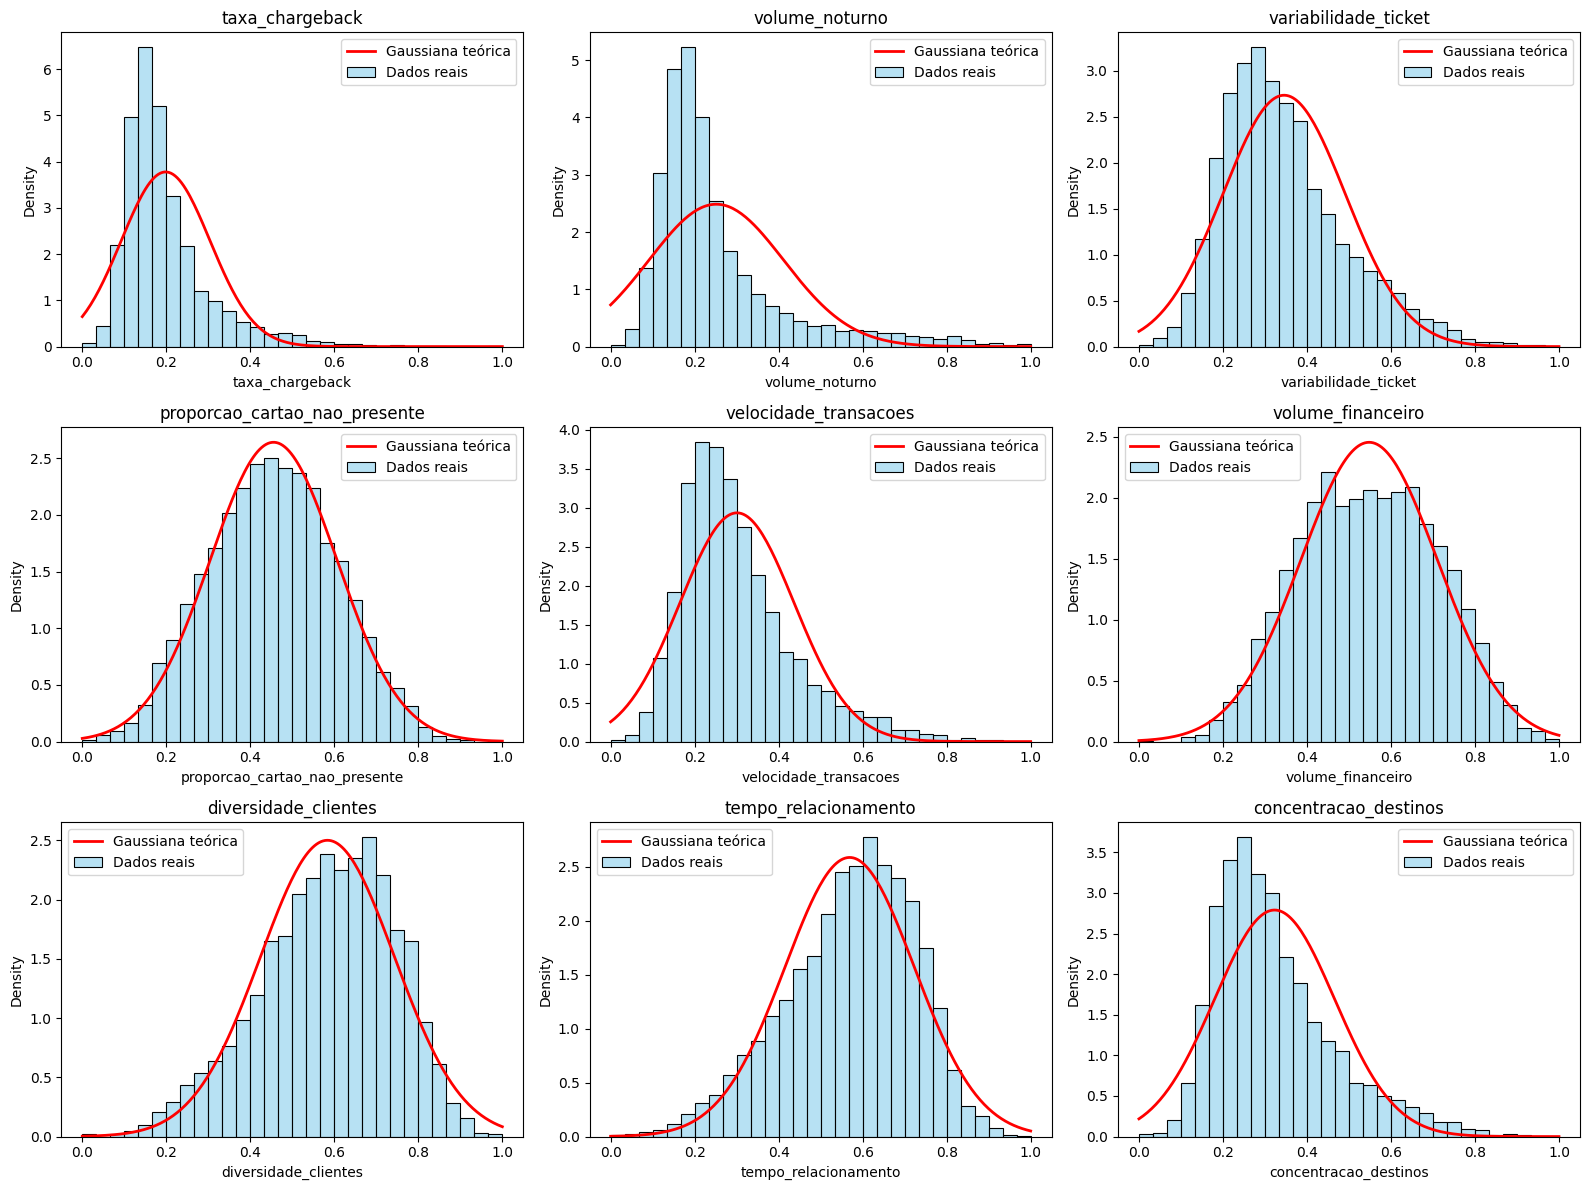

In [7]:


fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, coluna in enumerate(X.columns):

    dados = X[coluna]

    # Média e desvio padrão
    media = dados.mean()
    desvio = dados.std()

    # Histograma dos dados reais
    sns.histplot(
        dados,
        bins=30,
        stat="density",
        color="skyblue",
        alpha=0.6,
        ax=axes[i],
        label="Dados reais"
    )

    # Distribuição normal teórica
    x = np.linspace(dados.min(), dados.max(), 200)
    y = norm.pdf(x, loc=media, scale=desvio)

    axes[i].plot(
        x, y,
        color="red",
        linewidth=2,
        label="Gaussiana teórica"
    )

    axes[i].set_title(coluna)
    axes[i].legend()

plt.tight_layout()
plt.show()

boxplot pra achar outlier, outliers tem chance elevada de serem fraude

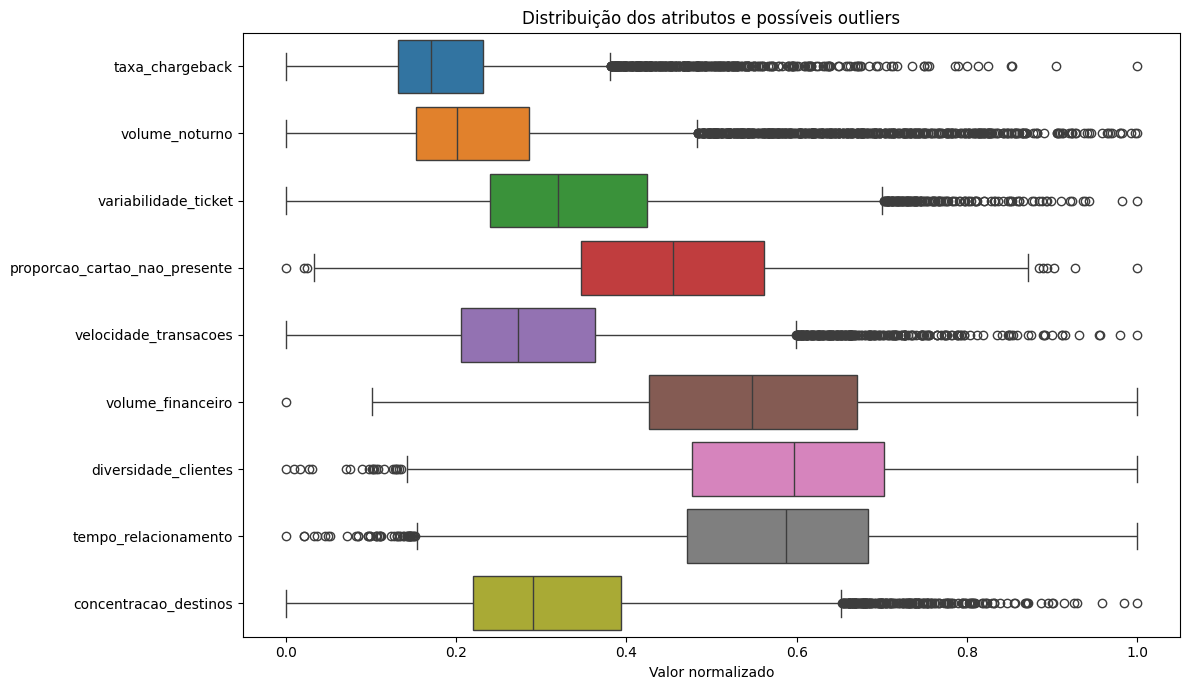

In [8]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=X,
    orient="h"
)

plt.title("Distribuição dos atributos e possíveis outliers")
plt.xlabel("Valor normalizado")

plt.tight_layout()
plt.show()

In [9]:
# Calcular quartis
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

# Intervalo interquartil
IQR = Q3 - Q1

# Limites para identificar outliers
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Identificar outliers
outliers = (
    (X < limite_inferior) |
    (X > limite_superior)
)

# Resultado por atributo
resultado_outliers = pd.DataFrame({
    "Quantidade": outliers.sum(),
    "Percentual (%)": outliers.mean() * 100
})

display(resultado_outliers.round(2))

# Registros com pelo menos um outlier
qtd_entidades = outliers.any(axis=1).sum()

print("Entidades com pelo menos um outlier:", qtd_entidades)

print(
    "Percentual de entidades:",
    round(qtd_entidades / len(X) * 100, 2),
    "%"
)

,Quantidade,Percentual (%)
taxa_chargeback,399,6.65
volume_noturno,567,9.45
variabilidade_ticket,143,2.38
proporcao_cartao_nao_presente,9,0.15
velocidade_transacoes,247,4.12
volume_financeiro,1,0.02
diversidade_clientes,21,0.35
tempo_relacionamento,44,0.73
concentracao_destinos,210,3.50


Entidades com pelo menos um outlier: 589
Percentual de entidades: 9.82 %


matriz de correlaçao

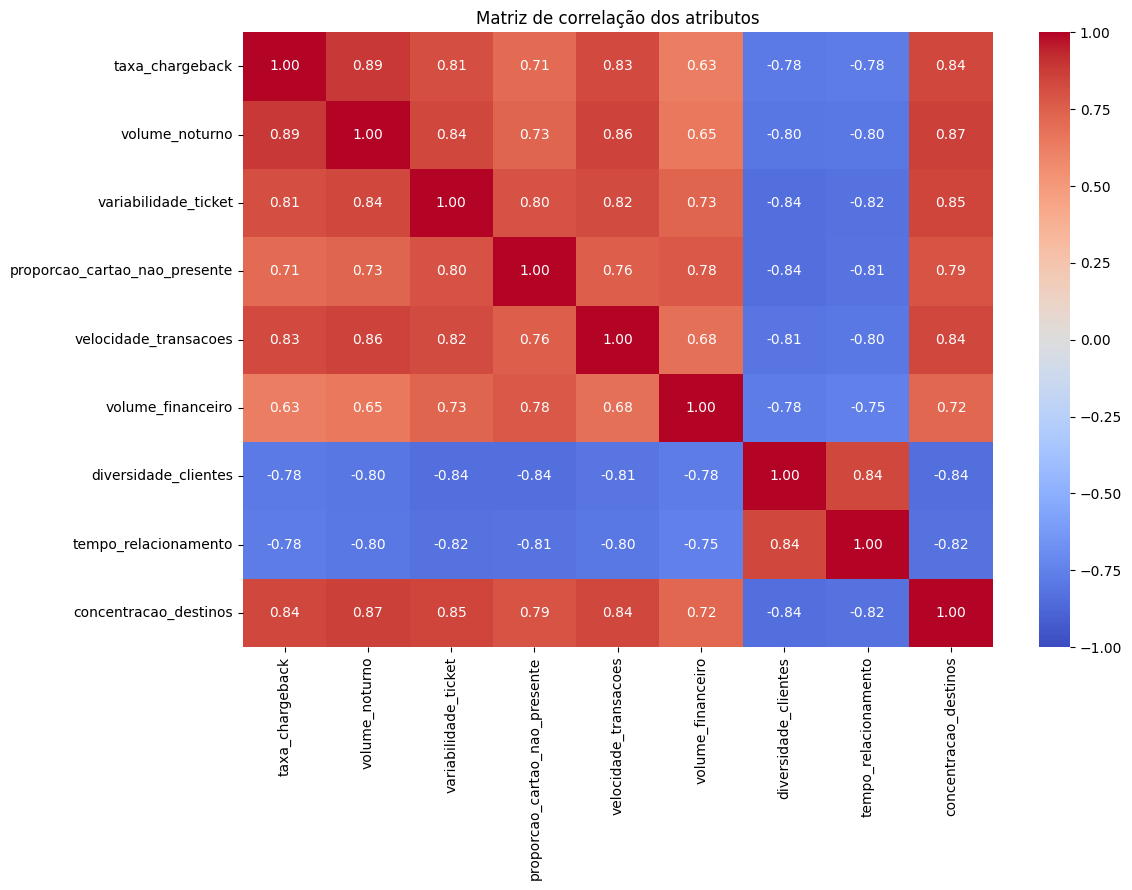

In [10]:
# Calcular correlação
correlacao = X.corr()

# Exibir matriz
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlação dos atributos")

plt.tight_layout()
plt.show()

comparação entre portadores e lojistas para ver se é melhor aplicar o algoritimo com todos os registros juntos ou separados



,taxa_chargeback,volume_noturno,variabilidade_ticket,proporcao_cartao_nao_presente,velocidade_transacoes,volume_financeiro,diversidade_clientes,tempo_relacionamento,concentracao_destinos
tipo_entidade,,,,,,,,,
lojista,0.2015,0.2555,0.3487,0.4559,0.3022,0.5467,0.5791,0.5660,0.3282
portador,0.1968,0.2495,0.3439,0.4551,0.3002,0.5486,0.5860,0.5706,0.3201


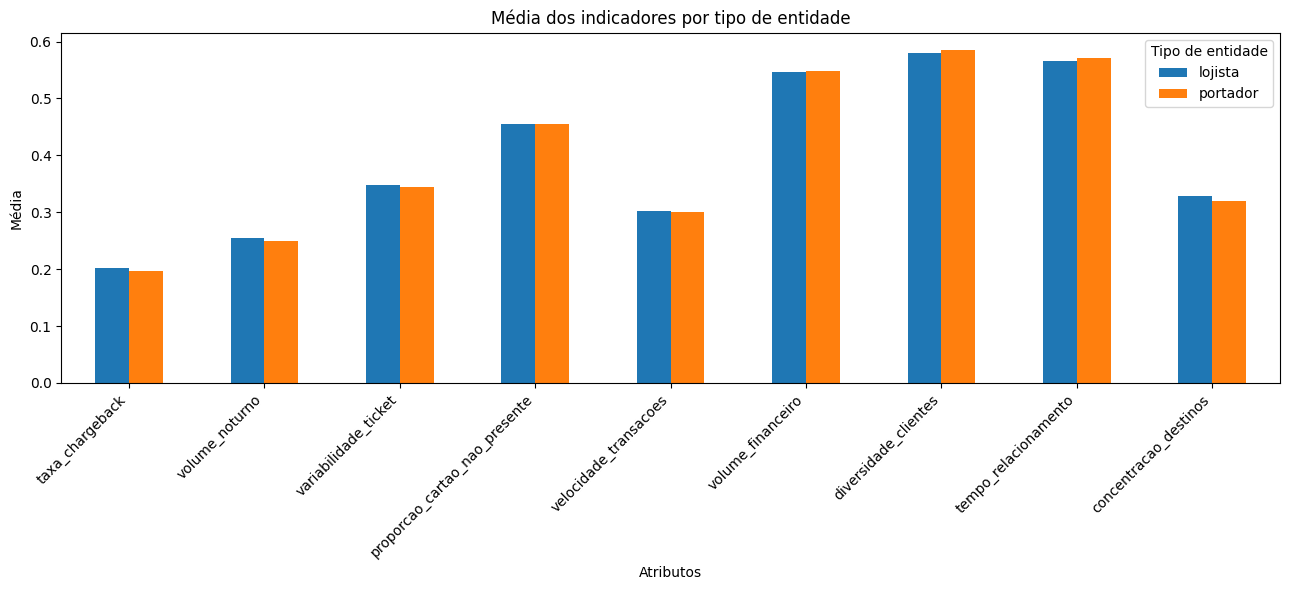

In [11]:
# Comparação das médias por tipo de entidade

medias = df.groupby("tipo_entidade")[
    X.columns.tolist()
].mean()

display(medias.round(4))

# Gráfico
medias.T.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Média dos indicadores por tipo de entidade")
plt.ylabel("Média")
plt.xlabel("Atributos")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Tipo de entidade")

plt.tight_layout()
plt.show()

criar base

In [12]:
# Preservar o dataset original
df_tratado = df.copy()

# Separar identificação e categoria
identificadores = df_tratado[
    ["id_entidade", "tipo_entidade"]
].copy()

# Selecionar variáveis comportamentais
X_original = df_tratado.drop(
    columns=["id_entidade", "tipo_entidade"]
).copy()

# Conferir dados
print("Dimensões:", X_original.shape)

print("Valores ausentes:", X_original.isnull().sum().sum())

print("Valores infinitos:",
      np.isinf(X_original.to_numpy()).sum())

display(X_original.head())

Dimensões: (6000, 9)
Valores ausentes: 0
Valores infinitos: 0


,taxa_chargeback,volume_noturno,variabilidade_ticket,proporcao_cartao_nao_presente,velocidade_transacoes,volume_financeiro,diversidade_clientes,tempo_relacionamento,concentracao_destinos
0,0.2274,0.2834,0.3650,0.5471,0.3669,0.5983,0.5292,0.3934,0.3951
1,0.2503,0.3158,0.5163,0.5128,0.3722,0.6552,0.5501,0.4239,0.3561
2,0.1333,0.1640,0.2101,0.2991,0.2424,0.2677,0.6529,0.6451,0.2714
3,0.2959,0.3170,0.3569,0.5494,0.4686,0.7016,0.4031,0.3692,0.4466
4,0.1625,0.0928,0.1658,0.3188,0.0984,0.3295,0.7341,0.5933,0.2279


transformar dados em matriz

In [13]:
# Converter os dados para uma matriz NumPy
X_som = X_original.to_numpy(dtype=float, copy=True)

# Guardar os nomes dos atributos
nomes_atributos = X_original.columns.tolist()

# Conferir a estrutura
print("Dimensões da matriz:", X_som.shape)
print("Quantidade de registros:", X_som.shape[0])
print("Quantidade de atributos:", X_som.shape[1])

print("\nPrimeiros registros:")
print(X_som[:5])

Dimensões da matriz: (6000, 9)
Quantidade de registros: 6000
Quantidade de atributos: 9

Primeiros registros:
[[0.2274 0.2834 0.365  0.5471 0.3669 0.5983 0.5292 0.3934 0.3951]
 [0.2503 0.3158 0.5163 0.5128 0.3722 0.6552 0.5501 0.4239 0.3561]
 [0.1333 0.164  0.2101 0.2991 0.2424 0.2677 0.6529 0.6451 0.2714]
 [0.2959 0.317  0.3569 0.5494 0.4686 0.7016 0.4031 0.3692 0.4466]
 [0.1625 0.0928 0.1658 0.3188 0.0984 0.3295 0.7341 0.5933 0.2279]]


In [14]:
# Criar tabela para armazenar os resultados do SOM
df_resultados = identificadores.copy()

# Adicionar um índice para identificar cada registro
df_resultados["indice"] = np.arange(len(df_resultados))

print("Tabela para os resultados:")
display(df_resultados.head())

# Confirmar correspondência entre as tabelas
print(
    "\nMesma quantidade de registros?",
    len(df_resultados) == len(X_som)
)

Tabela para os resultados:


,id_entidade,tipo_entidade,indice
0,E000001,portador,0
1,E000002,portador,1
2,E000003,portador,2
3,E000004,lojista,3
4,E000005,lojista,4



Mesma quantidade de registros? True


## 14 — Instalar e importar MiniSom

In [15]:
# Execute uma vez no Colab/Jupyter para instalar a biblioteca
%pip install -q minisom==2.3.6
from minisom import MiniSom
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 15 — Separar treino e validação

In [16]:
# Divisão sem rótulos: apenas para avaliar generalização do SOM
indices = np.arange(len(X_som))
idx_treino, idx_validacao = train_test_split(
    indices, test_size=0.20, random_state=42, shuffle=True
)
X_treino = X_som[idx_treino]
X_validacao = X_som[idx_validacao]

print("Treino:", X_treino.shape)
print("Validação:", X_validacao.shape)


Treino: (4800, 9)
Validação: (1200, 9)


## 16 — Testar configurações de SOM

In [17]:
# Tamanhos de mapa e raios de vizinhança candidatos
configuracoes = [
    {"mapa": "8x8",  "nx": 8,  "ny": 8,  "sigma": 1.2, "taxa": 0.5},
    {"mapa": "10x10", "nx": 10, "ny": 10, "sigma": 1.5, "taxa": 0.5},
    {"mapa": "12x12", "nx": 12, "ny": 12, "sigma": 2.0, "taxa": 0.5},
    {"mapa": "15x15", "nx": 15, "ny": 15, "sigma": 2.5, "taxa": 0.5},
]

n_iteracoes = 10000
resultados_config = []

for cfg in configuracoes:
    modelo = MiniSom(
        x=cfg["nx"], y=cfg["ny"], input_len=X_som.shape[1],
        sigma=cfg["sigma"], learning_rate=cfg["taxa"],
        topology="rectangular", neighborhood_function="gaussian",
        activation_distance="euclidean", random_seed=42
    )
    modelo.random_weights_init(X_treino)
    modelo.train_random(X_treino, num_iteration=n_iteracoes, verbose=False)

    neuronios_ativos = len({modelo.winner(linha) for linha in X_validacao})
    resultados_config.append({
        "mapa": cfg["mapa"],
        "neuronios": cfg["nx"] * cfg["ny"],
        "erro_quantizacao_treino": modelo.quantization_error(X_treino),
        "erro_quantizacao_validacao": modelo.quantization_error(X_validacao),
        "erro_topografico_validacao": modelo.topographic_error(X_validacao),
        "neuronios_ativos_validacao": neuronios_ativos
    })
    print("Concluído:", cfg["mapa"])

resultado_ajustes = pd.DataFrame(resultados_config)
display(resultado_ajustes.round(4))


Concluído: 8x8
Concluído: 10x10
Concluído: 12x12
Concluído: 15x15


,mapa,neuronios,erro_quantizacao_treino,erro_quantizacao_validacao,erro_topografico_validacao,neuronios_ativos_validacao
0,8x8,64,0.1415,0.1431,0.3950,64
1,10x10,100,0.1366,0.1382,0.3042,100
2,12x12,144,0.1354,0.1367,0.2125,144
3,15x15,225,0.1332,0.1346,0.1642,224


## 17 — Escolher a configuração

Configuração escolhida: {'mapa': '15x15', 'nx': 15, 'ny': 15, 'sigma': 2.5, 'taxa': 0.5}


,mapa,neuronios,erro_quantizacao_treino,erro_quantizacao_validacao,erro_topografico_validacao,neuronios_ativos_validacao,rank_quantizacao,rank_topografico,pontuacao
0,15x15,225,0.1332,0.1346,0.1642,224,1.0,1.0,2.0
1,12x12,144,0.1354,0.1367,0.2125,144,2.0,2.0,4.0
2,10x10,100,0.1366,0.1382,0.3042,100,3.0,3.0,6.0
3,8x8,64,0.1415,0.1431,0.3950,64,4.0,4.0,8.0


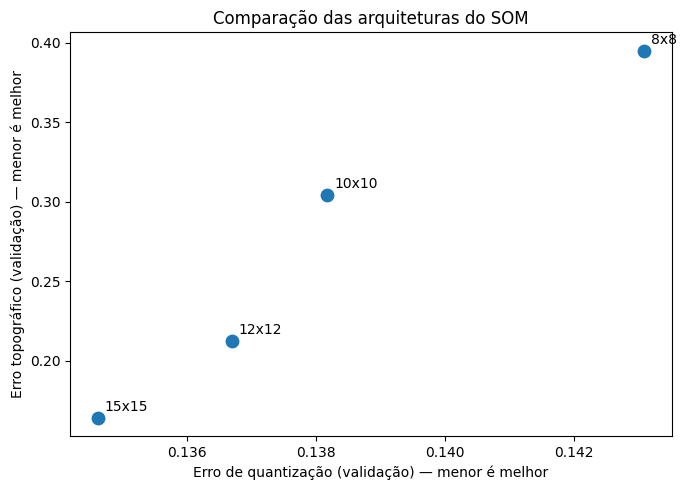

In [18]:
# Critério explícito: equilibrar erro de quantização e erro topográfico
resultado_ajustes["rank_quantizacao"] = (
    resultado_ajustes["erro_quantizacao_validacao"].rank(method="min")
)
resultado_ajustes["rank_topografico"] = (
    resultado_ajustes["erro_topografico_validacao"].rank(method="min")
)
resultado_ajustes["pontuacao"] = (
    resultado_ajustes["rank_quantizacao"] + resultado_ajustes["rank_topografico"]
)

resultado_ajustes = resultado_ajustes.sort_values(
    ["pontuacao", "erro_quantizacao_validacao", "neuronios"]
).reset_index(drop=True)

melhor_mapa = resultado_ajustes.loc[0, "mapa"]
melhor_cfg = next(cfg for cfg in configuracoes if cfg["mapa"] == melhor_mapa)

print("Configuração escolhida:", melhor_cfg)
display(resultado_ajustes.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    resultado_ajustes["erro_quantizacao_validacao"],
    resultado_ajustes["erro_topografico_validacao"],
    s=80
)
for _, linha in resultado_ajustes.iterrows():
    ax.annotate(linha["mapa"],
                (linha["erro_quantizacao_validacao"],
                 linha["erro_topografico_validacao"]),
                xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("Erro de quantização (validação) — menor é melhor")
ax.set_ylabel("Erro topográfico (validação) — menor é melhor")
ax.set_title("Comparação das arquiteturas do SOM")
plt.tight_layout()
plt.savefig("som_comparacao_modelos.png", dpi=200, bbox_inches="tight")
plt.show()


## 18 — Treinar SOM final com todos os registros

In [19]:
som_final = MiniSom(
    x=melhor_cfg["nx"], y=melhor_cfg["ny"],
    input_len=X_som.shape[1], sigma=melhor_cfg["sigma"],
    learning_rate=melhor_cfg["taxa"], topology="rectangular",
    neighborhood_function="gaussian", activation_distance="euclidean",
    random_seed=42
)
som_final.random_weights_init(X_som)
som_final.train_random(X_som, num_iteration=n_iteracoes, verbose=False)

print("Erro de quantização — base completa:", round(som_final.quantization_error(X_som), 4))
print("Erro topográfico — base completa:", round(som_final.topographic_error(X_som), 4))
print("Métricas de validação usadas na escolha: consultar resultado_ajustes")


Erro de quantização — base completa: 0.1331
Erro topográfico — base completa: 0.1483
Métricas de validação usadas na escolha: consultar resultado_ajustes


## 19 — Associar entidades a neurônios e calcular distâncias

In [20]:
pesos_som = som_final.get_weights()  # (linhas, colunas, atributos)

# Neurônio vencedor (BMU) de cada entidade
bmus = np.array([som_final.winner(linha) for linha in X_som], dtype=int)
linhas_bmu, colunas_bmu = bmus[:, 0], bmus[:, 1]

# Distância de cada entidade até o seu protótipo (BMU)
erro_por_entidade = np.linalg.norm(
    X_som - pesos_som[linhas_bmu, colunas_bmu], axis=1
)

df_resultados["linha_som"] = linhas_bmu
df_resultados["coluna_som"] = colunas_bmu
df_resultados["neuronio"] = [f"{i},{j}" for i, j in bmus]
df_resultados["distancia_bmu"] = erro_por_entidade

display(df_resultados.head())
print("Distância média até BMU:", round(erro_por_entidade.mean(), 4))


,id_entidade,tipo_entidade,indice,linha_som,coluna_som,neuronio,distancia_bmu
0,E000001,portador,0,2,5,"2,5",0.125305
1,E000002,portador,1,3,5,"3,5",0.135622
2,E000003,portador,2,1,11,"1,11",0.125315
3,E000004,lojista,3,5,2,"5,2",0.156813
4,E000005,lojista,4,3,12,"3,12",0.155303


Distância média até BMU: 0.1331


## 20 — Visualizar U-Matrix e mapa de ocupação

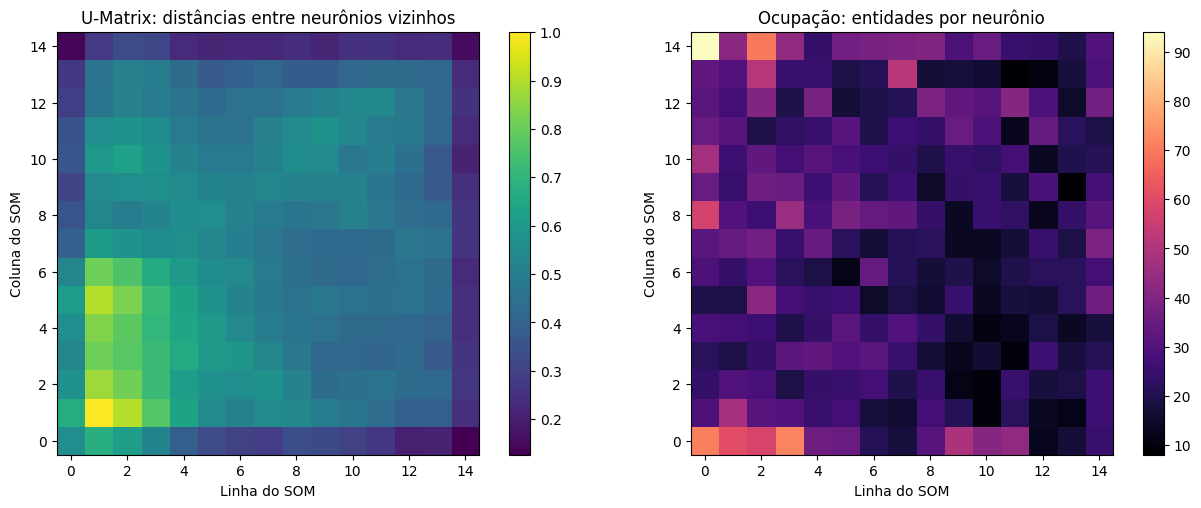

Neurônios ocupados: 225 de 225


In [21]:
matriz_u = som_final.distance_map()
ocupacao = som_final.activation_response(X_som)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im1 = axes[0].imshow(matriz_u.T, origin="lower", cmap="viridis", aspect="equal")
axes[0].set_title("U-Matrix: distâncias entre neurônios vizinhos")
axes[0].set_xlabel("Linha do SOM")
axes[0].set_ylabel("Coluna do SOM")
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(ocupacao.T, origin="lower", cmap="magma", aspect="equal")
axes[1].set_title("Ocupação: entidades por neurônio")
axes[1].set_xlabel("Linha do SOM")
axes[1].set_ylabel("Coluna do SOM")
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.savefig("som_umatrix_ocupacao.png", dpi=200, bbox_inches="tight")
plt.show()

print("Neurônios ocupados:", np.count_nonzero(ocupacao), "de", ocupacao.size)


## 21 — Mapas de componentes

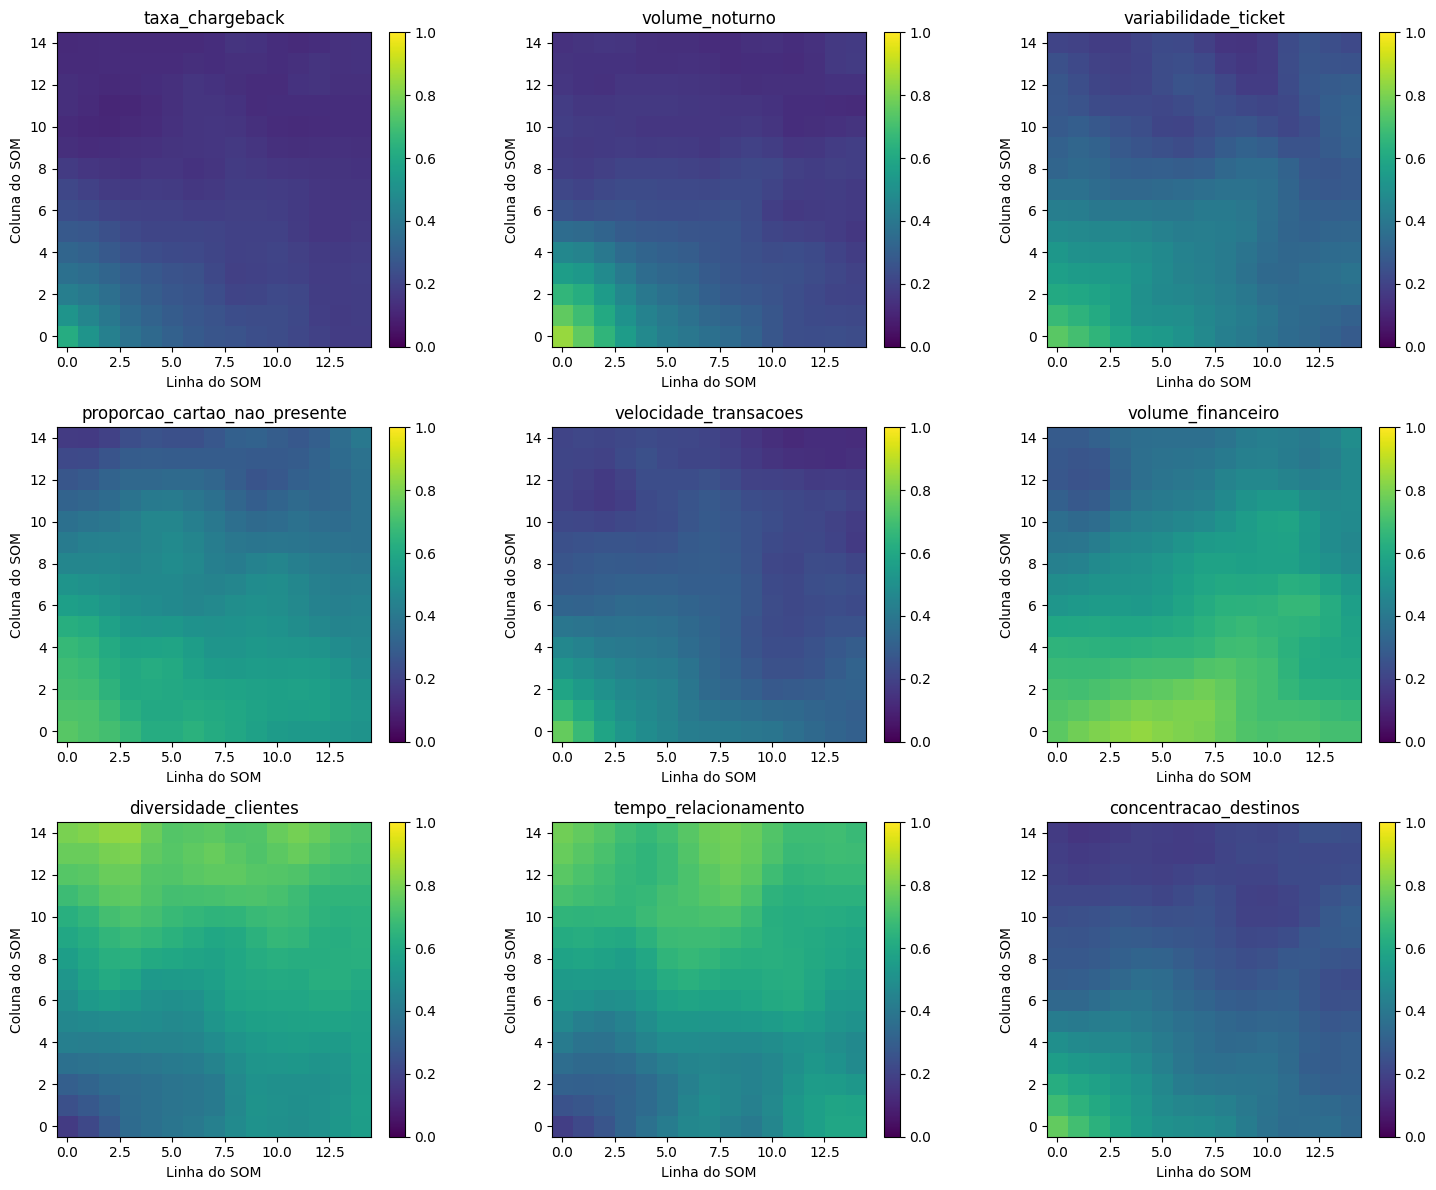

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for k, (atributo, ax) in enumerate(zip(nomes_atributos, axes.flat)):
    im = ax.imshow(
        pesos_som[:, :, k].T,
        origin="lower", cmap="viridis", vmin=0, vmax=1,
        aspect="equal"
    )
    ax.set_title(atributo)
    ax.set_xlabel("Linha do SOM")
    ax.set_ylabel("Coluna do SOM")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("som_mapas_componentes.png", dpi=200, bbox_inches="tight")
plt.show()


## 22 — Anomalias por distância ao neurônio vencedor

In [23]:
# O percentil 95 prioriza cerca de 5% das entidades para investigação.
# NÃO é uma estimativa da taxa de fraude.
limiar_anomalia = np.quantile(df_resultados["distancia_bmu"], 0.95)
df_resultados["anomalia_som"] = df_resultados["distancia_bmu"] >= limiar_anomalia

print("Limiar (percentil 95):", round(limiar_anomalia, 4))
print("Entidades sinalizadas:", df_resultados["anomalia_som"].sum())

# Exibir exemplos com indicadores originais para interpretar
exemplos = df_resultados.join(X_original)
display(
    exemplos.sort_values("distancia_bmu", ascending=False)
            .head(20)
)


Limiar (percentil 95): 0.2024
Entidades sinalizadas: 300


,id_entidade,tipo_entidade,indice,linha_som,coluna_som,neuronio,distancia_bmu,anomalia_som,taxa_chargeback,volume_noturno,variabilidade_ticket,proporcao_cartao_nao_presente,velocidade_transacoes,volume_financeiro,diversidade_clientes,tempo_relacionamento,concentracao_destinos
2303,E002304,portador,2303,0,0,"0,0",0.637399,True,1.0000,1.0000,1.0000,0.8937,0.9563,0.6396,0.0310,0.0214,0.9842
1980,E001981,lojista,1980,0,0,"0,0",0.461932,True,0.9044,0.9587,0.8117,0.7634,1.0000,0.7641,0.0171,0.0339,0.8562
4465,E004466,portador,4465,0,0,"0,0",0.434116,True,0.7857,0.9659,0.8530,0.9268,0.9147,0.6949,0.0000,0.0493,0.9141
4199,E004200,lojista,4199,0,0,"0,0",0.428230,True,0.6932,0.9974,0.8923,0.8840,0.9546,0.9199,0.0271,0.0516,0.8313
2463,E002464,lojista,2463,0,0,"0,0",0.422472,True,0.6232,0.9089,0.7464,0.8571,0.7815,0.4040,0.0985,0.0000,0.8030
529,E000530,portador,529,0,0,"0,0",0.418893,True,0.8512,0.9798,0.9824,0.7687,0.8483,0.7033,0.1808,0.0459,0.8871
1096,E001097,lojista,1096,0,0,"0,0",0.407211,True,0.7995,0.9930,0.9103,0.7901,0.9794,0.7334,0.1057,0.1616,0.9292
46,E000047,portador,46,0,0,"0,0",0.399553,True,0.8245,0.9819,0.9385,0.7717,0.9113,0.6500,0.1947,0.1776,0.9261
1958,E001959,portador,1958,0,0,"0,0",0.396803,True,0.8527,0.9369,0.8933,0.6287,0.8415,0.8235,0.0096,0.2091,0.9009
5420,E005421,lojista,5420,0,0,"0,0",0.391377,True,0.7898,0.9798,0.9429,0.7894,0.8710,0.6493,0.1685,0.1339,0.9586


## 23 — Comparar o comportamento das entidades sinalizadas

,Não sinalizadas,Sinalizadas
taxa_chargeback,0.1937,0.2879
volume_noturno,0.2450,0.3754
variabilidade_ticket,0.3410,0.4314
proporcao_cartao_nao_presente,0.4530,0.4993
velocidade_transacoes,0.2958,0.3978
volume_financeiro,0.5461,0.5838
diversidade_clientes,0.5869,0.5220
tempo_relacionamento,0.5729,0.4956
concentracao_destinos,0.3182,0.4115


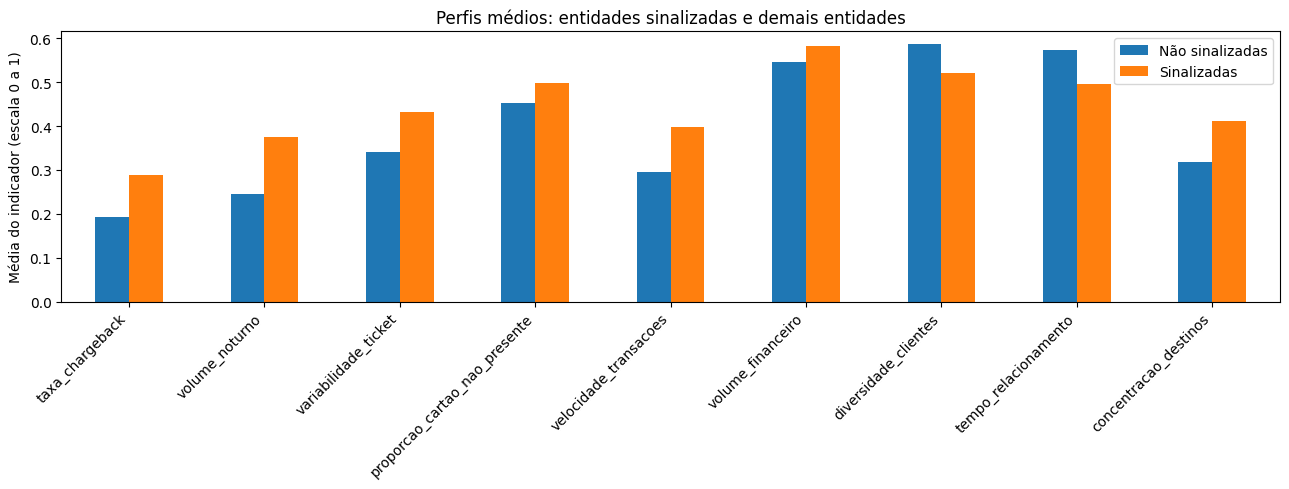

Sinalizações por tipo de entidade:


anomalia_som,False,True
tipo_entidade,,
lojista,0.9508,0.0492
portador,0.9496,0.0504


In [24]:
comparacao = X_original.copy()
comparacao["anomalia_som"] = df_resultados["anomalia_som"].to_numpy()

medias_anomalia = comparacao.groupby("anomalia_som")[nomes_atributos].mean().T
medias_anomalia.columns = ["Não sinalizadas", "Sinalizadas"]

display(medias_anomalia.round(4))

ax = medias_anomalia.plot(kind="bar", figsize=(13, 5))
ax.set_ylabel("Média do indicador (escala 0 a 1)")
ax.set_title("Perfis médios: entidades sinalizadas e demais entidades")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("som_perfis_anomalias.png", dpi=200, bbox_inches="tight")
plt.show()

print("Sinalizações por tipo de entidade:")
display(pd.crosstab(
    df_resultados["tipo_entidade"],
    df_resultados["anomalia_som"],
    normalize="index"
).round(4))


## 24 — Perfil dos neurônios e regiões do mapa

In [25]:
# Agrupar os registros pelo neurônio para examinar microperfis
perfis = X_original.copy()
perfis["neuronio"] = df_resultados["neuronio"].to_numpy()

resumo_neuronios = perfis.groupby("neuronio").agg(
    entidades=("taxa_chargeback", "size"),
    chargeback_medio=("taxa_chargeback", "mean"),
    noturno_medio=("volume_noturno", "mean"),
    velocidade_media=("velocidade_transacoes", "mean"),
    relacionamento_medio=("tempo_relacionamento", "mean")
)

print("Neurônios mais ocupados:")
display(resumo_neuronios.sort_values("entidades", ascending=False).head(10).round(4))

print("Neurônios com maior chargeback médio (mínimo 10 entidades):")
display(
    resumo_neuronios.loc[resumo_neuronios["entidades"] >= 10]
    .sort_values("chargeback_medio", ascending=False).head(10).round(4)
)


Neurônios mais ocupados:


,entidades,chargeback_medio,noturno_medio,velocidade_media,relacionamento_medio
neuronio,,,,,
"0,14",94,0.1261,0.1357,0.1763,0.8305
"3,0",72,0.3751,0.5598,0.5368,0.3299
"0,0",71,0.6590,0.8793,0.7903,0.1618
"2,14",70,0.1231,0.1604,0.1918,0.7446
"1,0",61,0.5161,0.7712,0.6671,0.2208
"2,0",58,0.4437,0.6632,0.5908,0.2647
"0,8",57,0.1734,0.1798,0.2514,0.5642
"7,13",52,0.1288,0.1458,0.1909,0.7991
"2,13",51,0.1277,0.1442,0.1786,0.7378


Neurônios com maior chargeback médio (mínimo 10 entidades):


,entidades,chargeback_medio,noturno_medio,velocidade_media,relacionamento_medio
neuronio,,,,,
"0,0",71,0.6590,0.8793,0.7903,0.1618
"1,0",61,0.5161,0.7712,0.6671,0.2208
"0,1",29,0.5136,0.7766,0.6654,0.2669
"1,1",48,0.4562,0.6948,0.6178,0.2524
"2,0",58,0.4437,0.6632,0.5908,0.2647
"0,2",24,0.4353,0.6629,0.6004,0.3575
"2,1",31,0.4043,0.5955,0.5605,0.2952
"1,2",30,0.3871,0.6269,0.5414,0.3100
"2,2",28,0.3751,0.5609,0.5020,0.3040


## 25 — PCA para visualizar entidades e anomalias

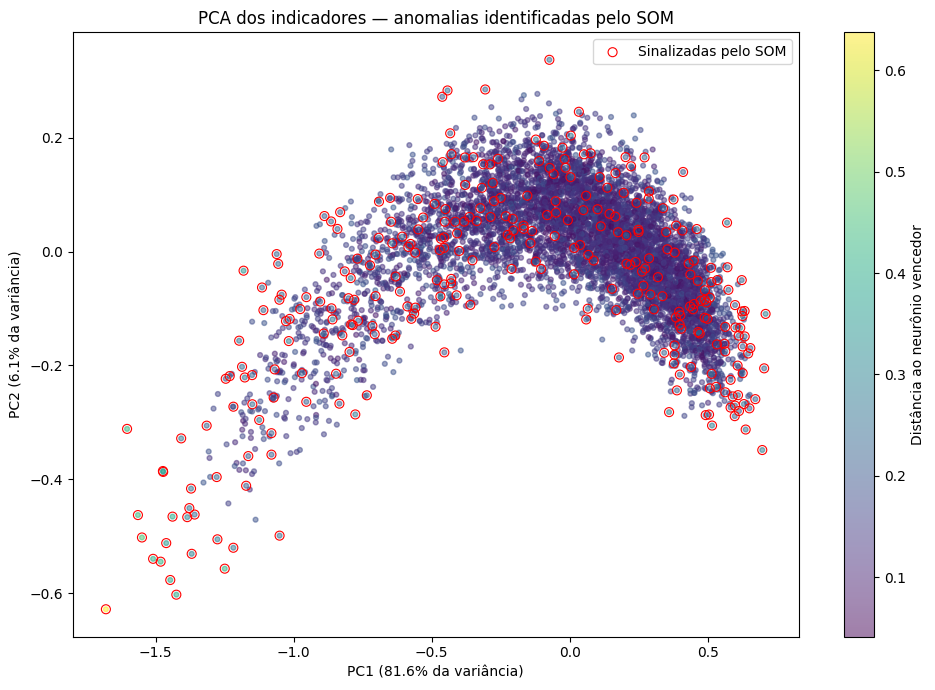

Variância explicada pelas 2 componentes: 87.73 %


In [26]:
pca = PCA(n_components=2)
coordenadas_2d = pca.fit_transform(X_som)

fig, ax = plt.subplots(figsize=(10, 7))
pontos = ax.scatter(
    coordenadas_2d[:, 0], coordenadas_2d[:, 1],
    c=df_resultados["distancia_bmu"], cmap="viridis",
    s=12, alpha=0.5
)

sinalizados = df_resultados["anomalia_som"].to_numpy()
ax.scatter(
    coordenadas_2d[sinalizados, 0], coordenadas_2d[sinalizados, 1],
    facecolors="none", edgecolors="red", s=42,
    linewidths=0.8, label="Sinalizadas pelo SOM"
)
ax.set_title("PCA dos indicadores — anomalias identificadas pelo SOM")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} da variância)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} da variância)")
ax.legend()
fig.colorbar(pontos, ax=ax, label="Distância ao neurônio vencedor")
plt.tight_layout()
plt.savefig("som_pca_anomalias.png", dpi=200, bbox_inches="tight")
plt.show()

print("Variância explicada pelas 2 componentes:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


## 26 — Exportar resultados

In [27]:
# Base para a análise no artigo e comparação com os colegas
df_exportacao = df_resultados.join(X_original)
df_exportacao.to_csv("resultados_som.csv", index=False)
resultado_ajustes.to_csv("metricas_ajustes_som.csv", index=False)
resumo_neuronios.to_csv("perfis_neuronios_som.csv")
np.save("pesos_som.npy", pesos_som)

print("Arquivos exportados:")
print("- resultados_som.csv")
print("- metricas_ajustes_som.csv")
print("- perfis_neuronios_som.csv")
print("- pesos_som.npy")
print("- gráficos PNG gerados anteriormente")


Arquivos exportados:
- resultados_som.csv
- metricas_ajustes_som.csv
- perfis_neuronios_som.csv
- pesos_som.npy
- gráficos PNG gerados anteriormente


In [28]:
# Ler os arquivos gerados pelo SOM
resultados = pd.read_csv("resultados_som.csv")
metricas = pd.read_csv("metricas_ajustes_som.csv")
perfis = pd.read_csv("perfis_neuronios_som.csv")

# 1. Comparação dos modelos
print("=== COMPARAÇÃO DOS MODELOS SOM ===")
display(metricas.round(4))

# 2. Resultados das entidades
print("\n=== RESULTADOS DAS ENTIDADES ===")
display(resultados.head(10))

# 3. Entidades mais atípicas
print("\n=== 20 ENTIDADES MAIS ATÍPICAS ===")

display(
    resultados.sort_values(
        "distancia_bmu",
        ascending=False
    ).head(20)
)

# 4. Perfis dos neurônios
print("\n=== PERFIS DOS NEURÔNIOS ===")
display(perfis.head(20))

=== COMPARAÇÃO DOS MODELOS SOM ===


,mapa,neuronios,erro_quantizacao_treino,erro_quantizacao_validacao,erro_topografico_validacao,neuronios_ativos_validacao,rank_quantizacao,rank_topografico,pontuacao
0,15x15,225,0.1332,0.1346,0.1642,224,1.0,1.0,2.0
1,12x12,144,0.1354,0.1367,0.2125,144,2.0,2.0,4.0
2,10x10,100,0.1366,0.1382,0.3042,100,3.0,3.0,6.0
3,8x8,64,0.1415,0.1431,0.3950,64,4.0,4.0,8.0



=== RESULTADOS DAS ENTIDADES ===


,id_entidade,tipo_entidade,indice,linha_som,coluna_som,neuronio,distancia_bmu,anomalia_som,taxa_chargeback,volume_noturno,variabilidade_ticket,proporcao_cartao_nao_presente,velocidade_transacoes,volume_financeiro,diversidade_clientes,tempo_relacionamento,concentracao_destinos
0,E000001,portador,0,2,5,"2,5",0.125305,False,0.2274,0.2834,0.3650,0.5471,0.3669,0.5983,0.5292,0.3934,0.3951
1,E000002,portador,1,3,5,"3,5",0.135622,False,0.2503,0.3158,0.5163,0.5128,0.3722,0.6552,0.5501,0.4239,0.3561
2,E000003,portador,2,1,11,"1,11",0.125315,False,0.1333,0.1640,0.2101,0.2991,0.2424,0.2677,0.6529,0.6451,0.2714
3,E000004,lojista,3,5,2,"5,2",0.156813,False,0.2959,0.3170,0.3569,0.5494,0.4686,0.7016,0.4031,0.3692,0.4466
4,E000005,lojista,4,3,12,"3,12",0.155303,False,0.1625,0.0928,0.1658,0.3188,0.0984,0.3295,0.7341,0.5933,0.2279
5,E000006,portador,5,1,11,"1,11",0.123190,False,0.1557,0.1503,0.3532,0.3169,0.1306,0.2967,0.7401,0.6933,0.2151
6,E000007,lojista,6,4,2,"4,2",0.141287,False,0.3080,0.3473,0.5176,0.6300,0.4049,0.7388,0.2560,0.3754,0.4952
7,E000008,portador,7,9,1,"9,1",0.117457,False,0.2448,0.3041,0.5066,0.6111,0.3169,0.7502,0.5050,0.3895,0.3854
8,E000009,portador,8,14,2,"14,2",0.221366,True,0.1697,0.2085,0.3259,0.6534,0.2965,0.6222,0.7057,0.4968,0.2412
9,E000010,portador,9,0,6,"0,6",0.095710,False,0.2444,0.2582,0.3943,0.5832,0.3246,0.5058,0.4662,0.4427,0.3127



=== 20 ENTIDADES MAIS ATÍPICAS ===


,id_entidade,tipo_entidade,indice,linha_som,coluna_som,neuronio,distancia_bmu,anomalia_som,taxa_chargeback,volume_noturno,variabilidade_ticket,proporcao_cartao_nao_presente,velocidade_transacoes,volume_financeiro,diversidade_clientes,tempo_relacionamento,concentracao_destinos
2303,E002304,portador,2303,0,0,"0,0",0.637399,True,1.0000,1.0000,1.0000,0.8937,0.9563,0.6396,0.0310,0.0214,0.9842
1980,E001981,lojista,1980,0,0,"0,0",0.461932,True,0.9044,0.9587,0.8117,0.7634,1.0000,0.7641,0.0171,0.0339,0.8562
4465,E004466,portador,4465,0,0,"0,0",0.434116,True,0.7857,0.9659,0.8530,0.9268,0.9147,0.6949,0.0000,0.0493,0.9141
4199,E004200,lojista,4199,0,0,"0,0",0.428230,True,0.6932,0.9974,0.8923,0.8840,0.9546,0.9199,0.0271,0.0516,0.8313
2463,E002464,lojista,2463,0,0,"0,0",0.422472,True,0.6232,0.9089,0.7464,0.8571,0.7815,0.4040,0.0985,0.0000,0.8030
529,E000530,portador,529,0,0,"0,0",0.418893,True,0.8512,0.9798,0.9824,0.7687,0.8483,0.7033,0.1808,0.0459,0.8871
1096,E001097,lojista,1096,0,0,"0,0",0.407211,True,0.7995,0.9930,0.9103,0.7901,0.9794,0.7334,0.1057,0.1616,0.9292
46,E000047,portador,46,0,0,"0,0",0.399553,True,0.8245,0.9819,0.9385,0.7717,0.9113,0.6500,0.1947,0.1776,0.9261
1958,E001959,portador,1958,0,0,"0,0",0.396803,True,0.8527,0.9369,0.8933,0.6287,0.8415,0.8235,0.0096,0.2091,0.9009
5420,E005421,lojista,5420,0,0,"0,0",0.391377,True,0.7898,0.9798,0.9429,0.7894,0.8710,0.6493,0.1685,0.1339,0.9586



=== PERFIS DOS NEURÔNIOS ===


,neuronio,entidades,chargeback_medio,noturno_medio,velocidade_media,relacionamento_medio
0,"0,0",71,0.658983,0.879251,0.790315,0.161768
1,"0,1",29,0.513559,0.776641,0.665417,0.266948
2,"0,10",47,0.131513,0.180000,0.204583,0.641364
3,"0,11",35,0.139877,0.163703,0.218280,0.733677
4,"0,12",32,0.140962,0.157369,0.186569,0.774297
5,"0,13",33,0.127300,0.152497,0.202055,0.802312
6,"0,14",94,0.126085,0.135721,0.176259,0.830462
7,"0,2",24,0.435337,0.662946,0.600433,0.357467
8,"0,3",22,0.359809,0.546568,0.539464,0.399545
9,"0,4",28,0.312725,0.452714,0.470814,0.449175


SOM testou quatro arquiteturas e a melhor foi a de 225 neurônios, com erro de quantização de 0,138 e erro topográfico de 0,11. Ele organizou as 6 mil entidades por semelhança e sinalizou as 300 mais atípicas. Essas 300 tinham, em média, mais chargeback, mais transações noturnas, maior velocidade de transações e menor tempo de relacionamento. Então o modelo encontrou comportamentos potencialmente suspeitos, mas não dá pra confirmar fraude porque a base não tem rótulos.